# Spanish syllable statistics

Statistics over the syllables in `data/silabas.db` (build it first with `python build_db.py`):
the most and least frequent syllables, how syllables are shaped, and a table of every
syllable **pattern** against its vowel.

A pattern is a syllable with its vowel taken out: the consonants before the vowel
(onset), a dash, and the consonants after it (coda).

| Pattern | Syllables |
| --- | --- |
| `B` | BA, BE, BI, BO, BU |
| `BL` | BLA, BLE, BLI, BLO, BLU |
| `-N` | AN, EN, IN, ON, UN |
| `BR-N` | BRAN, BREN, BRIN, BRON, BRUN |
| `-` | A, E, I, O, U (a bare vowel) |

Accents are ignored (`ción` counts as `cion`), and a final `y` is a vowel (*hoy* has the
diphthong OI).

**Digraphs** are two letters for a single sound, so they count as one consonant:

- `CH`, `LL`, `RR` (*chi-co*, *ca-lle*, *pe-rro*).
- `QU`, `GU` before E or I, where the U is silent: *que* is `QU` + E, not Q + the diphthong
  UE, and *quie-to* is `QU` + the diphthong IE, not a triphthong. With a dieresis the U is
  pronounced, so *pin-güi-no* is G + the diphthong UI. Before A or O the U is always a vowel:
  *cua-dro*, *quó-rum* and *gua-po* have the diphthongs UA/UO.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, LogNorm

# What a "count" means everywhere below:
#   "lemmas" - number of base-form words (infinitives, masculine singular...) with the syllable
#   "forms"  - number of word forms (conjugations, plurals... included) with the syllable
#   "usage"  - occurrences in spoken Spanish (OpenSubtitles word frequency)
MEASURE = "lemmas"

DB_PATH = Path("data/silabas.db")
pd.set_option("display.max_rows", 100)

# Reference sequential ramp (one hue, light -> dark) and chart inks
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#898781", "#e1e0d9"
CMAP = LinearSegmentedColormap.from_list("blues", BLUE_RAMP)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "font.size": 10,
})

## Load the syllables

In [2]:
con = sqlite3.connect(DB_PATH)
df = pd.read_sql_query(
    "SELECT s.syllable, s.pos, w.word, w.n_syllables, w.freq, w.is_lemma "
    "FROM syllables s JOIN words w ON w.id = s.word_id",
    con,
)
words = pd.read_sql_query("SELECT word, n_syllables, freq, is_lemma FROM words", con)
con.close()

ACUTE = str.maketrans("áéíóúÁÉÍÓÚ", "aeiouAEIOU")
df["plain"] = df["syllable"].str.lower().str.translate(ACUTE)
df["weight"] = {"lemmas": df["is_lemma"], "forms": 1, "usage": df["freq"]}[MEASURE]
if MEASURE == "lemmas":
    words = words[words["is_lemma"] == 1]
data = df[df["weight"] > 0]
print(f"{len(df):,} syllables in {df['word'].nunique():,} word forms; "
      f"counting by {MEASURE!r}: {data['weight'].sum():,} in total")

3,007,388 syllables in 703,054 word forms; counting by 'lemmas': 342,928 in total


## Splitting a syllable into onset, vowel and coda

In [3]:
VOWELS = set("aeiouü")


def split_syllable(s):
    """'bran' -> ('br', 'a', 'n'); 'que' -> ('qu', 'e', ''); 'hoy' -> ('h', 'oi', '')."""
    # y is a vowel unless a vowel follows it (ya, yo are consonant + vowel)
    is_vowel = [ch in VOWELS or (ch == "y" and (i + 1 == len(s) or s[i + 1] not in VOWELS))
                for i, ch in enumerate(s)]
    if not any(is_vowel):
        return s, "", ""
    start = is_vowel.index(True)
    end = start
    while end < len(s) and is_vowel[end]:
        end += 1
    onset, nucleus, coda = s[:start], s[start:end], s[end:]
    # silent u in que/qui, gue/gui: the digraphs QU, GU (güe/güi keep the u, it is pronounced)
    if len(nucleus) > 1 and nucleus[0] == "u" and nucleus[1] in "ei" and onset.endswith(("q", "g")):
        onset, nucleus = onset + "u", nucleus[1:]
    return onset, nucleus.replace("y", "i").replace("ü", "u"), coda


# digraphs: two letters, one sound (qu/gu only reach an onset before e/i, see above)
DIGRAPHS = ("ch", "ll", "rr", "qu", "gu")


def consonants(cluster):
    """'chr' -> ['ch', 'r']: the consonant sounds of an onset or coda."""
    units, i = [], 0
    while i < len(cluster):
        n = 2 if cluster[i:i + 2] in DIGRAPHS else 1
        units.append(cluster[i:i + n])
        i += n
    return units


def onset_type(onset):
    units = consonants(onset)
    if not units:
        return "No onset"
    if len(units) > 1:
        return "Cluster"
    return "Digraph" if units[0] in DIGRAPHS else "Single consonant"


def pattern_of(onset, coda):
    if not onset and not coda:
        return "-"
    return onset.upper() + ("-" + coda.upper() if coda else "")


def vowel_group(nucleus):
    if len(nucleus) == 1:
        return nucleus.upper()
    return {0: "No vowel", 2: "Diphthong", 3: "Triphthong"}.get(len(nucleus), "Other")


checks = ["que", "quien", "quie", "quo", "cua", "gue", "guion", "güe", "güi", "gua", "guau",
          "buey", "hoy", "chi", "llan", "rre", "bran", "a", "an"]
display(pd.DataFrame(
    [(s, *split_syllable(s)) for s in checks],
    columns=["syllable", "onset", "nucleus", "coda"],
).assign(pattern=lambda d: [pattern_of(o, c) for o, c in zip(d.onset, d.coda)],
         onset_type=lambda d: d.onset.map(onset_type),
         vowel=lambda d: d.nucleus.map(vowel_group)).set_index("syllable").T)

syl = data.groupby("plain")["weight"].sum().rename("count").to_frame()
# example word: the most used word containing the syllable
syl["example"] = (data.sort_values("freq", ascending=False).drop_duplicates("plain")
                  .set_index("plain")["word"])
syl[["onset", "nucleus", "coda"]] = [split_syllable(s) for s in syl.index]
syl["pattern"] = [pattern_of(o, c) for o, c in zip(syl["onset"], syl["coda"])]
syl["onset_type"] = syl["onset"].map(onset_type)
syl["vowel"] = syl["nucleus"].map(vowel_group)
syl = syl.sort_values("count", ascending=False)
print(f"{len(syl):,} distinct syllables, {syl['pattern'].nunique():,} patterns, "
      f"{syl['nucleus'].nunique()} vowel nuclei")
print("Left out of the pattern tables (letters and abbreviations without a vowel):",
      ", ".join(syl.index[syl["vowel"].isin(["No vowel", "Other"])]))
syl.head(10)

syllable,que,quien,quie,quo,cua,gue,guion,güe,güi,gua,guau,buey,hoy,chi,llan,rre,bran,a,an
onset,qu,qu,qu,q,c,gu,gu,g,g,g,g,b,h,ch,ll,rr,br,,
nucleus,e,ie,ie,uo,ua,e,io,ue,ui,ua,uau,uei,oi,i,a,e,a,a,a
coda,,n,,,,,n,,,,,,,,n,,n,,n
pattern,QU,QU-N,QU,Q,C,GU,GU-N,G,G,G,G,B,H,CH,LL-N,RR,BR-N,-,-N
onset_type,Digraph,Digraph,Digraph,Single consonant,Single consonant,Digraph,Digraph,Single consonant,Single consonant,Single consonant,Single consonant,Single consonant,Single consonant,Digraph,Digraph,Digraph,Cluster,No onset,No onset
vowel,E,Diphthong,Diphthong,Diphthong,Diphthong,E,Diphthong,Diphthong,Diphthong,Diphthong,Triphthong,Triphthong,Diphthong,I,A,E,A,A,A


2,856 distinct syllables, 775 patterns, 32 vowel nuclei
Left out of the pattern tables (letters and abbreviations without a vowel): q, r, pts, h, pp, cl, ch, cfr, cf, pl, pg, rvd, s, p, c, bv, cm, sr, ss, t, bs, n, ms, j, blv, g, jhs, v, m, d, k, f, w, vs, ll, kg, x, km, z, b, l, ñ


,count,example,onset,nucleus,coda,pattern,onset_type,vowel
plain,,,,,,,,
a,11189,a,,a,,-,No onset,A
te,9419,te,t,e,,T,Single consonant,E
ta,8261,esta,t,a,,T,Single consonant,A
to,7218,esto,t,o,,T,Single consonant,O
co,7051,como,c,o,,C,Single consonant,O
ca,6995,casa,c,a,,C,Single consonant,A
ti,5875,ti,t,i,,T,Single consonant,I
ra,5614,para,r,a,,R,Single consonant,A
do,5581,todo,d,o,,D,Single consonant,O


## Overview

In [4]:
total = syl["count"].sum()
share = syl["count"].cumsum() / total
summary = pd.Series({
    "Words": f"{len(words):,}",
    "Syllables (with repetition)": f"{total:,}",
    "Distinct syllables": f"{len(syl):,}",
    "Mean syllables per word": f"{words['n_syllables'].mean():.2f}",
    "Syllables covering 50% of all": int((share < 0.5).sum() + 1),
    "Syllables covering 90% of all": int((share < 0.9).sum() + 1),
    "Syllables covering 99% of all": int((share < 0.99).sum() + 1),
    "Syllables seen only once": int((syl["count"] == 1).sum()),
}, name=MEASURE)
summary.to_frame()

,lemmas
Words,"91,744"
Syllables (with repetition),"342,928"
Distinct syllables,"2,856"
Mean syllables per word,3.74
Syllables covering 50% of all,43
Syllables covering 90% of all,308
Syllables covering 99% of all,1241
Syllables seen only once,867


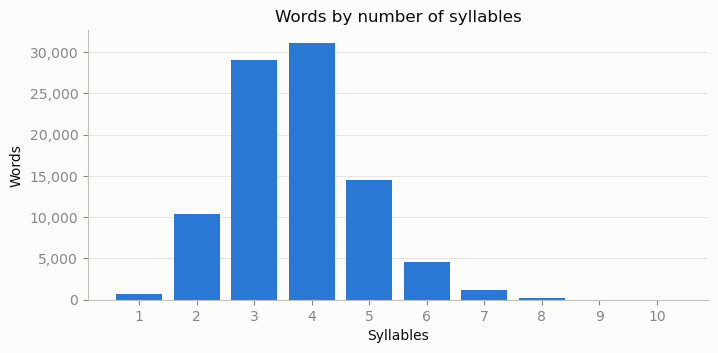

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
n = words["n_syllables"].value_counts().sort_index()
ax.bar(n.index, n.values, color=BLUE, width=0.8)
ax.set(title="Words by number of syllables", xlabel="Syllables", ylabel="Words")
ax.set_xticks(n.index)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="x", visible=False)
plt.show()

## Most frequent syllables

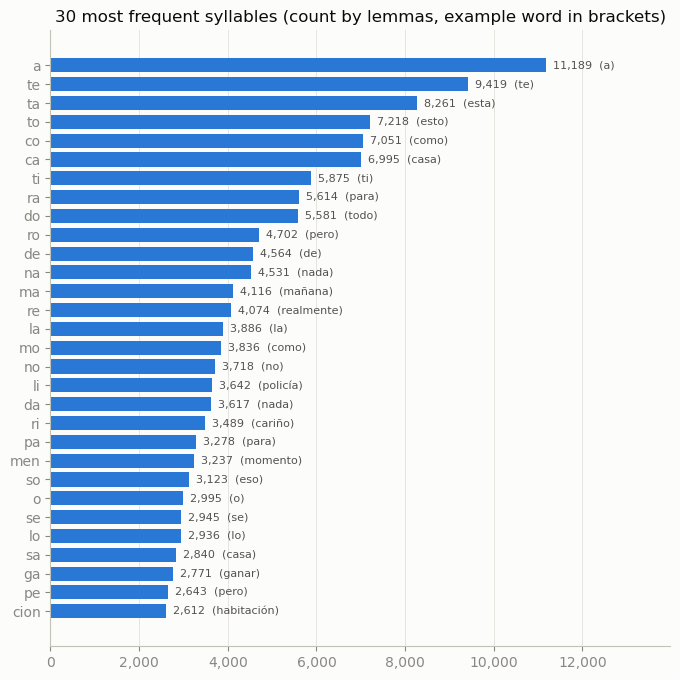

In [6]:
top = syl.head(30).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top.index, top["count"], color=BLUE, height=0.75)
for y, (c, ex) in enumerate(zip(top["count"], top["example"])):
    ax.text(c, y, f"  {c:,}  ({ex})", va="center", fontsize=8, color="#52514e")
ax.set(title=f"30 most frequent syllables (count by {MEASURE}, example word in brackets)")
ax.margins(x=0.25)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(axis="y", visible=False)
plt.show()

The same top 10 under each way of counting: dictionary entries, all word forms, and real usage.

In [7]:
def top_by(weight, n=10):
    return df.assign(w=weight).groupby("plain")["w"].sum().nlargest(n)

compare = pd.DataFrame({
    m: [f"{s}  ({c:,})" for s, c in top_by(w).items()]
    for m, w in {"lemmas": df["is_lemma"], "forms": 1, "usage": df["freq"]}.items()
}, index=range(1, 11))
compare

,lemmas,forms,usage
1,"a (11,189)","a (154,801)","a (30,267,668)"
2,"te (9,419)","re (89,298)","de (24,293,572)"
3,"ta (8,261)","mos (76,850)","es (22,020,063)"
4,"to (7,218)","ri (64,854)","que (21,358,209)"
5,"co (7,051)","ra (63,116)","no (17,624,040)"
6,"ca (6,995)","ta (61,381)","te (16,427,234)"
7,"ti (5,875)","ca (57,055)","do (15,656,941)"
8,"ra (5,614)","se (54,251)","ta (13,729,076)"
9,"do (5,581)","de (53,790)","la (12,382,235)"
10,"ro (4,702)","do (53,499)","ra (12,280,192)"


### First syllables

Which syllables most often start a word (what `find_words.py` searches first).

In [8]:
first = (data[data["pos"] == 0].groupby("plain")["weight"].sum()
         .nlargest(20).rename("count").to_frame())
first["share"] = (first["count"] / data.loc[data["pos"] == 0, "weight"].sum()).map("{:.1%}".format)
first

,count,share
plain,,
a,7700,8.4%
re,2667,2.9%
ca,2497,2.7%
en,2270,2.5%
es,2266,2.5%
de,2204,2.4%
des,1967,2.1%
in,1892,2.1%
co,1644,1.8%


## Least frequent syllables

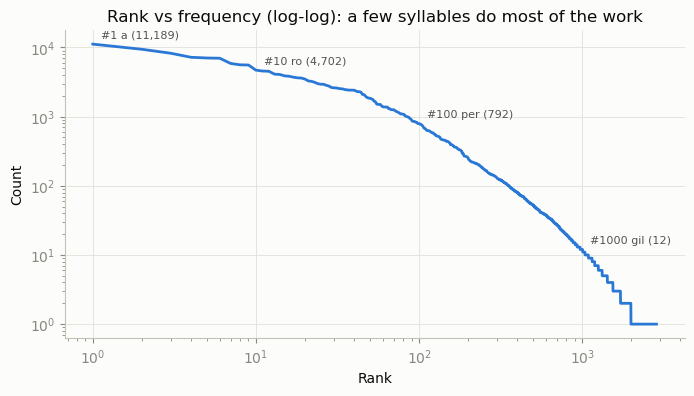

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ranks = np.arange(1, len(syl) + 1)
ax.loglog(ranks, syl["count"], color=BLUE, linewidth=2)
for r in (1, 10, 100, 1000):
    s = syl.iloc[r - 1]
    ax.annotate(f"#{r} {s.name} ({s['count']:,})", (r, s["count"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8, color="#52514e")
ax.set(title="Rank vs frequency (log-log): a few syllables do most of the work",
       xlabel="Rank", ylabel="Count")
plt.show()

In [10]:
rare = syl[syl["count"] <= 2].sort_values(["count", "pattern"])
print(f"{len(rare):,} syllables appear at most twice. A sample:")
rare.sample(min(40, len(rare)), random_state=1).sort_values("count")[
    ["count", "example", "pattern", "nucleus"]]

1,139 syllables appear at most twice. A sample:


,count,example,pattern,nucleus
plain,,,,
yuc,1,yucpa,Y-C,u
pso,1,psoriasis,PS,o
kal,1,akalché,K-L,a
rring,1,sparring,RR-NG,i
boh,1,bohrio,B-H,o
vert,1,sievert,V-RT,e
tou,1,genitourinario,T,ou
quark,1,quark,Q-RK,ua
grau,1,grauero,GR,au


## Syllable shapes (C = consonant sound, V = vowel)

A digraph is one C: *chi* and *que* are CV, *pe-rro* is CV-CV.

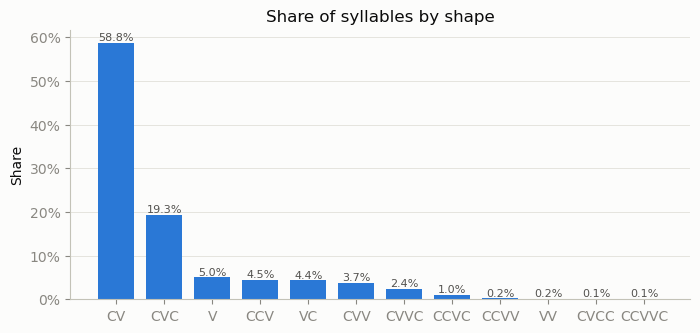

In [11]:
syl["shape"] = ["C" * len(consonants(o)) + "V" * len(n) + "C" * len(consonants(c))
                for o, n, c in zip(syl["onset"], syl["nucleus"], syl["coda"])]
shapes = syl.groupby("shape")["count"].sum().nlargest(12)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(shapes.index, shapes.values / total, color=BLUE, width=0.75)
for x, v in enumerate(shapes.values / total):
    ax.text(x, v, f"{v:.1%}", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set(title="Share of syllables by shape", ylabel="Share")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", visible=False)
plt.show()

## Patterns by vowel

One row per pattern, ordered by how frequent the pattern is, and one column per vowel
nucleus: the five vowels, then every diphthong and every triphthong, each group ordered
by frequency. Each cell is the count of syllables with that pattern and nucleus (row
`BR-N`, column `A` is the count of BRAN; row `B-N`, column `IE` is BIEN).

In [12]:
GROUPS = {1: "Vowel", 2: "Diphthong", 3: "Triphthong"}
voiced = syl[syl["nucleus"].str.len().between(1, 3)]
table = voiced.pivot_table(index="pattern", columns="nucleus", values="count",
                           aggfunc="sum", fill_value=0)
by_freq = table.sum().sort_values(ascending=False).index
order = (["a", "e", "i", "o", "u"]
         + [n for n in by_freq if len(n) == 2] + [n for n in by_freq if len(n) == 3])
table = table[order]
table.columns = pd.MultiIndex.from_tuples([(GROUPS[len(n)], n.upper()) for n in order])
value_cols = list(table.columns)
table[("", "Total")] = table.sum(axis=1)
table = table.sort_values(("", "Total"), ascending=False)
table.index.name = "Pattern"


def style_counts(t):
    cols = [c for c in t.columns if c[1] != "Total"]
    vals = t[cols].replace(0, np.nan)
    styler = (t.style
              .background_gradient(cmap=CMAP, subset=cols, gmap=np.log10(vals), axis=None)
              .format(lambda v: f"{v:,.0f}" if v else "")
              .set_properties(**{"text-align": "right", "font-size": "11px"}))
    # vertical line where vowels end and diphthongs, triphthongs and Total start
    line = "border-left: 2px solid #52514e"
    starts = [i for i in range(1, t.shape[1]) if t.columns[i][0] != t.columns[i - 1][0]]
    styles = [{"selector": f".col{i}", "props": line} for i in starts]
    styles += [{"selector": f"th.col_heading.level{lvl}.col{i}", "props": line}
               for i in starts for lvl in (0, 1)]
    return styler.set_table_styles(styles, overwrite=False)


print(f"{len(table)} patterns x {len(value_cols)} nuclei; colour is log-scaled")
style_counts(table)

760 patterns x 31 nuclei; colour is log-scaled


### Heatmap of the most frequent patterns

The same table as a picture, for the 60 most frequent patterns and the 25 most frequent
nuclei. Colour is on a log scale so rare cells stay visible next to *ta* or *ra*.

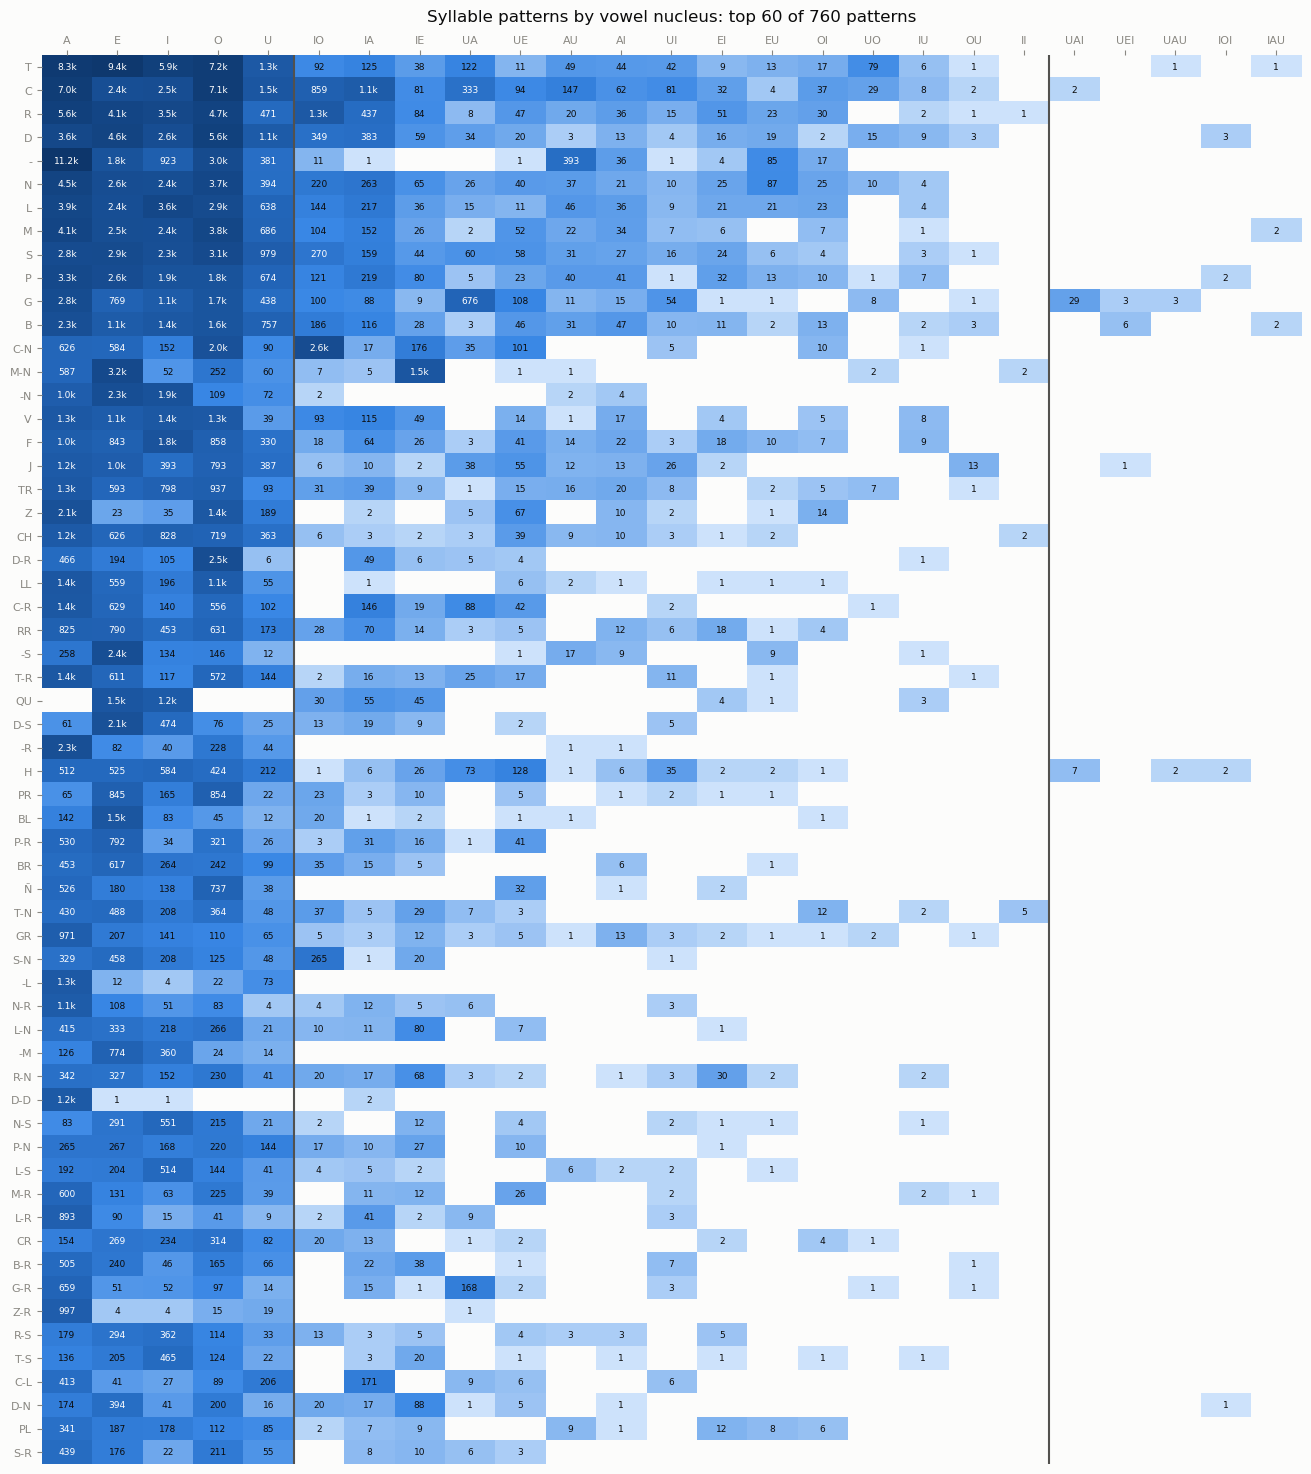

In [13]:
def heatmap(t, title, n_rows=60):
    t = t.head(n_rows)
    vals = t.to_numpy(dtype=float)
    masked = np.ma.masked_equal(vals, 0)
    fig, ax = plt.subplots(figsize=(0.55 * t.shape[1] + 2.5, 0.28 * len(t) + 1.5))
    norm = LogNorm(vmin=max(1, masked.min()), vmax=masked.max())
    ax.imshow(masked, cmap=CMAP, norm=norm, aspect="auto")
    ax.set_xticks(range(t.shape[1]), [c[1] for c in t.columns], fontsize=8)
    ax.set_yticks(range(len(t)), t.index, fontsize=8)
    ax.xaxis.tick_top()
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    # thin separators between the vowel / diphthong / triphthong groups
    groups = [c[0] for c in t.columns]
    for j in range(1, len(groups)):
        if groups[j] != groups[j - 1]:
            ax.axvline(j - 0.5, color="#52514e", linewidth=1.5)
    for (i, j), v in np.ndenumerate(vals):
        if v:
            label = f"{v / 1000:.1f}k" if v >= 1000 else f"{v:.0f}"
            ax.text(j, i, label, ha="center", va="center", fontsize=6.5,
                    color="white" if norm(v) > 0.6 else INK)
    ax.set_title(title, pad=24)
    plt.show()


top_nuclei = table[value_cols].sum().sort_values(ascending=False).index[:25]
heatmap(table[[c for c in value_cols if c in top_nuclei]],
        f"Syllable patterns by vowel nucleus: top 60 of {len(table)} patterns")

### Patterns by type of onset

How the syllables split between no onset, a single consonant, a digraph (`CH`, `LL`,
`RR`, `QU`, `GU`) or a cluster (`BR`, `PL`...), and then the digraph patterns on their own.

In [14]:
onset_types = voiced.groupby("pattern")["onset_type"].first()
by_type = (voiced.groupby("onset_type")["count"].sum().to_frame("Syllables")
           .assign(Patterns=onset_types.value_counts())
           .sort_values("Syllables", ascending=False))
by_type["Share"] = (by_type["Syllables"] / by_type["Syllables"].sum()).map("{:.1%}".format)
by_type

,Syllables,Patterns,Share
onset_type,,,
Single consonant,272458,444,79.5%
No onset,33062,43,9.6%
Cluster,20045,209,5.8%
Digraph,17321,64,5.1%


In [15]:
digraphs = table[onset_types.reindex(table.index) == "Digraph"]
digraphs = digraphs.loc[:, digraphs.sum() > 0]  # drop nuclei never used after a digraph
style_counts(digraphs)